In [1]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPool2D, Dense, Flatten, Dropout, Rescaling, RandomFlip, RandomRotation, Input, Rescaling
import kagglehub
import os
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

In [2]:
#Downloading the flower from Kaggle
path = kagglehub.dataset_download("alxmamaev/flowers-recognition")
PATH_DATASET = os.path.join(path, "flowers")

SIZE_IMAGE = (128, 128) #Size of each image
SIZE_LOT = 32 #Batch size

#Training data
dataset_training = tf.keras.utils.image_dataset_from_directory(
    PATH_DATASET,
    validation_split=0.2,
    subset="training",
    seed=42,
    image_size=SIZE_IMAGE,
    batch_size=SIZE_LOT
)

#Validation data
dataset_validation = tf.keras.utils.image_dataset_from_directory(
    PATH_DATASET,
    validation_split=0.2,
    subset="validation",
    seed=42,
    image_size=SIZE_IMAGE,
    batch_size=SIZE_LOT
)

flowers_name = dataset_training.class_names
nb_class = len(flowers_name)
print(f"Flowers to recognize : {flowers_name}")

#Data augmentation : generate random variations of the images during the training (Flip, Rotation, Zoom)
data_augmentation = Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.1),
    tf.keras.layers.RandomZoom(0.1),
])

Using Colab cache for faster access to the 'flowers-recognition' dataset.
Found 4317 files belonging to 5 classes.
Using 3454 files for training.
Found 4317 files belonging to 5 classes.
Using 863 files for validation.
Flowers to recognize : ['daisy', 'dandelion', 'rose', 'sunflower', 'tulip']


In [3]:
from tensorflow.keras.layers import Input, Rescaling
from tensorflow.keras.applications import MobileNet

#Transfer Learning : load MobileNet pre-trained on ImageNet
conv_base = MobileNet(weights='imagenet', include_top=False, input_shape=(128, 128, 3))
conv_base.trainable = False

modele = Sequential()
modele.add(Input(shape=(128, 128, 3)))

#Generate image with random modification, (randomflip, rotation, zoom)
modele.add(data_augmentation)

#Normalization :  brings pixel values from [0,255] to [0,1]
modele.add(Rescaling(1./255))

#Adding the MobileNet database
modele.add(conv_base)

#Flatten : converts 2D feature maps to a 1D vector.
modele.add(Flatten())

#Dense Layer : learn to combine the MobileNet features for our flower recognition problem
#ReLU Activation --> max(0,x) : remove the negative value
modele.add(Dense(128, activation='relu'))

#Dropout at 0.5, randomly turn off half of the neurons at each batch during the training
#Prevent neurons from depending too much on each other, --> reduce the overfitting
modele.add(Dropout(0.5))

#Softmax : give a probability distribution to each class, sum() = 1
modele.add(Dense(nb_class, activation='softmax'))

modele.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

17225924/17225924 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [4]:
modele.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)
AUTOTUNE = tf.data.AUTOTUNE
dataset_training = dataset_training.cache().prefetch(buffer_size=AUTOTUNE)
dataset_validation = dataset_validation.cache().prefetch(buffer_size=AUTOTUNE)
historique = modele.fit(
    dataset_training,
    validation_data=dataset_validation,
    epochs=10,
)


Epoch 1/10
108/108 ━━━━━━━━━━━━━━━━━━━━ 82s 714ms/step - accuracy: 0.6720 - loss: 1.0865 - val_accuracy: 0.8169 - val_loss: 0.5099
Epoch 2/10
108/108 ━━━━━━━━━━━━━━━━━━━━ 71s 655ms/step - accuracy: 0.7507 - loss: 0.6858 - val_accuracy: 0.8308 - val_loss: 0.4608
Epoch 3/10
108/108 ━━━━━━━━━━━━━━━━━━━━ 69s 644ms/step - accuracy: 0.7750 - loss: 0.5992 - val_accuracy: 0.8424 - val_loss: 0.4328
Epoch 4/10
108/108 ━━━━━━━━━━━━━━━━━━━━ 70s 646ms/step - accuracy: 0.7953 - loss: 0.5735 - val_accuracy: 0.8308 - val_loss: 0.4875
Epoch 5/10
108/108 ━━━━━━━━━━━━━━━━━━━━ 92s 742ms/step - accuracy: 0.8005 - loss: 0.5225 - val_accuracy: 0.8482 - val_loss: 0.4625
Epoch 6/10
108/108 ━━━━━━━━━━━━━━━━━━━━ 71s 641ms/step - accuracy: 0.8034 - loss: 0.5232 - val_accuracy: 0.8517 - val_loss: 0.4425
Epoch 7/10
108/108 ━━━━━━━━━━━━━━━━━━━━ 79s 731ms/step - accuracy: 0.8390 - loss: 0.4614 - val_accuracy: 0.8494 - val_loss: 0.4997
Epoch 8/10
108/108 ━━━━━━━━━━━━━━━━━━━━ 83s 745ms/step - accuracy: 0.8431 - loss: 0

In [ ]:
#Fine-Tunning
conv_base.trainable = True
for layer in conv_base.layers[:-20]:
    layer.trainable = False

modele.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)
AUTOTUNE = tf.data.AUTOTUNE
dataset_entrainement = dataset_entrainement.cache().prefetch(buffer_size=AUTOTUNE)
dataset_validation = dataset_validation.cache().prefetch(buffer_size=AUTOTUNE)
historique = modele.fit(
    dataset_entrainement,
    validation_data=dataset_validation,
    epochs=10,
)


Epoch 1/10
108/108 ━━━━━━━━━━━━━━━━━━━━ 122s 1s/step - accuracy: 0.7999 - loss: 0.5483 - val_accuracy: 0.8621 - val_loss: 0.4461
Epoch 2/10
108/108 ━━━━━━━━━━━━━━━━━━━━ 121s 1s/step - accuracy: 0.8286 - loss: 0.4573 - val_accuracy: 0.8586 - val_loss: 0.4594
Epoch 3/10
108/108 ━━━━━━━━━━━━━━━━━━━━ 114s 1s/step - accuracy: 0.8309 - loss: 0.4563 - val_accuracy: 0.8575 - val_loss: 0.4494
Epoch 4/10
108/108 ━━━━━━━━━━━━━━━━━━━━ 116s 1s/step - accuracy: 0.8532 - loss: 0.3811 - val_accuracy: 0.8563 - val_loss: 0.4544
Epoch 5/10
108/108 ━━━━━━━━━━━━━━━━━━━━ 118s 1s/step - accuracy: 0.8457 - loss: 0.3944 - val_accuracy: 0.8575 - val_loss: 0.4485
Epoch 6/10
108/108 ━━━━━━━━━━━━━━━━━━━━ 114s 1s/step - accuracy: 0.8474 - loss: 0.3976 - val_accuracy: 0.8644 - val_loss: 0.4393
Epoch 7/10
108/108 ━━━━━━━━━━━━━━━━━━━━ 122s 1s/step - accuracy: 0.8535 - loss: 0.3794 - val_accuracy: 0.8598 - val_loss: 0.4519
Epoch 8/10
108/108 ━━━━━━━━━━━━━━━━━━━━ 111s 1s/step - accuracy: 0.8709 - loss: 0.3619 - val_accu

In [ ]:
#Connection to the drive & saving the model at the same time
from google.colab import drive
drive.mount('/content/drive', force_remount=True)
modele.save('/content/drive/MyDrive/mon_modele_fleurs.keras')

Mounted at /content/drive


File : tulip2.jpg           | TULIP      | Accuracy : 100.00 %


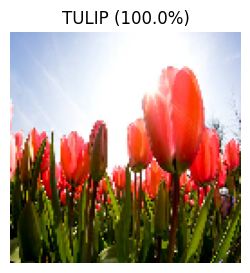

File : tulip1.jpg           | TULIP      | Accuracy :  99.98 %


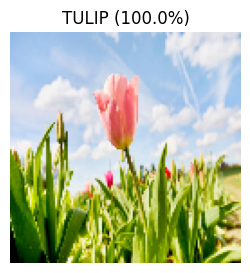

File : tulip.jpg            | TULIP      | Accuracy :  58.26 %


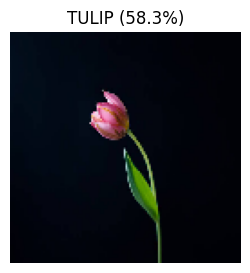

File : sunflower4.jpg       | SUNFLOWER  | Accuracy : 100.00 %


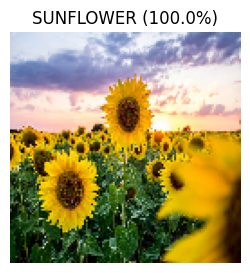

File : sunflower3.jpg       | SUNFLOWER  | Accuracy : 100.00 %


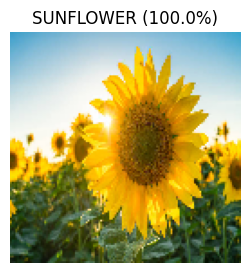

File : sunflower2.jpg       | SUNFLOWER  | Accuracy : 100.00 %


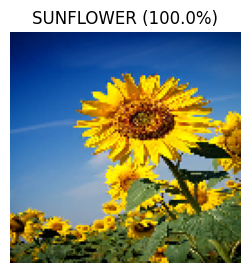

File : sunflower1.jpg       | SUNFLOWER  | Accuracy : 100.00 %


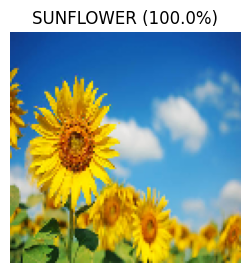

File : sunflower.jpg        | SUNFLOWER  | Accuracy :  99.99 %


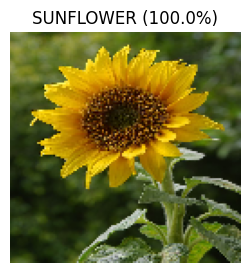

File : rose4.jpg            | TULIP      | Accuracy :  78.34 %


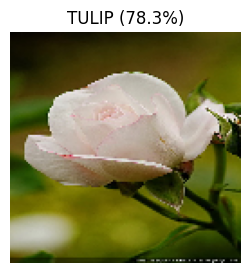

File : rose3.jpg            | ROSE       | Accuracy :  79.91 %


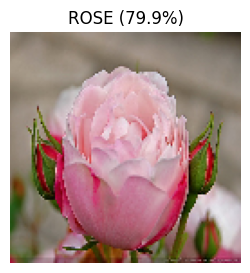

File : rose2.jpg            | TULIP      | Accuracy :  75.79 %


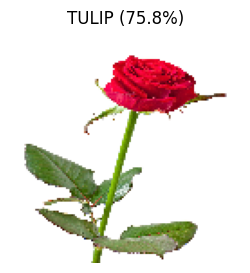

File : rose1.jpg            | ROSE       | Accuracy :  99.78 %


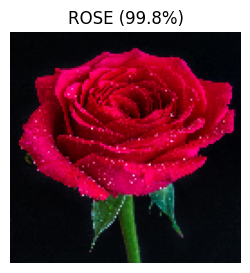

File : rose.jpeg            | ROSE       | Accuracy :  98.08 %


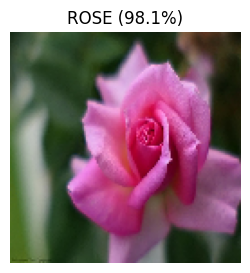

File : dandelions4.jpg      | DANDELION  | Accuracy : 100.00 %


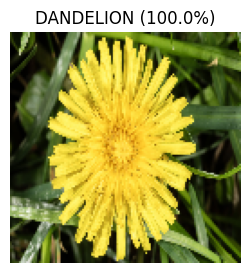

File : dandelions3.jpeg     | DANDELION  | Accuracy :  90.67 %


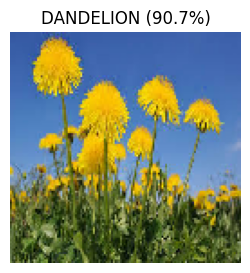

File : dandelions2.jpeg     | DANDELION  | Accuracy : 100.00 %


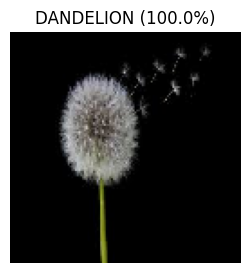

File : dandelions1.jpeg     | DANDELION  | Accuracy : 100.00 %


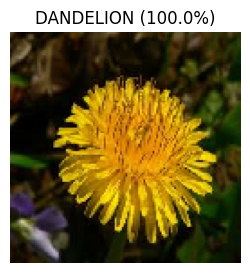

File : dandelions.jpg       | DANDELION  | Accuracy : 100.00 %


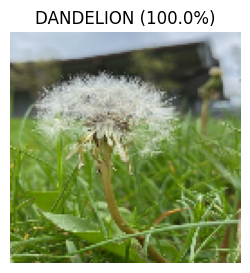

File : daisy4.jpg           | DAISY      | Accuracy : 100.00 %


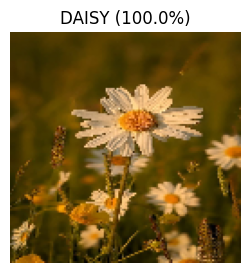

File : daisy3.jpg           | DAISY      | Accuracy :  99.99 %


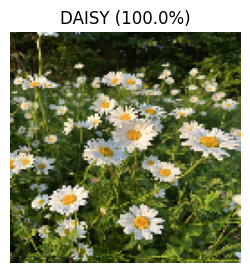

File : daisy2.jpg           | DAISY      | Accuracy : 100.00 %


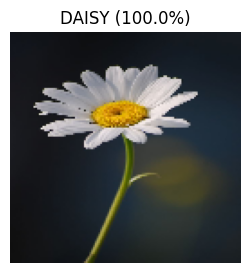

File : daisy1.jpg           | DAISY      | Accuracy : 100.00 %


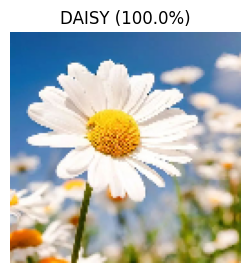

File : daisy.jpg            | DAISY      | Accuracy : 100.00 %


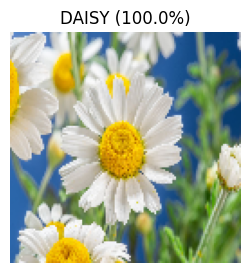

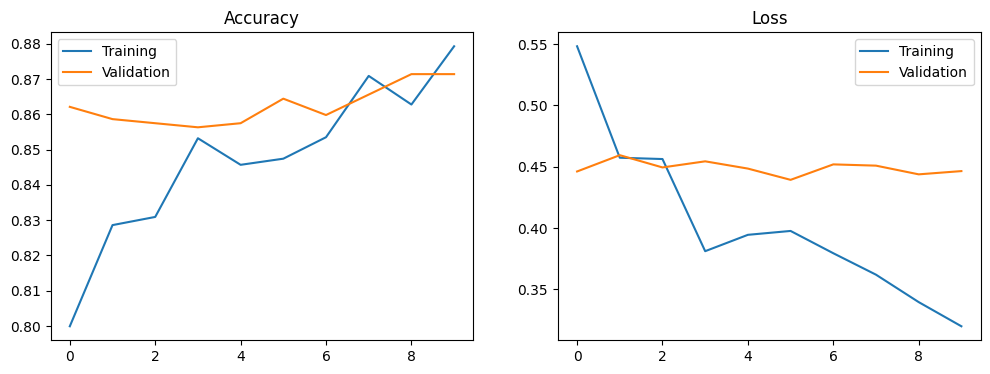

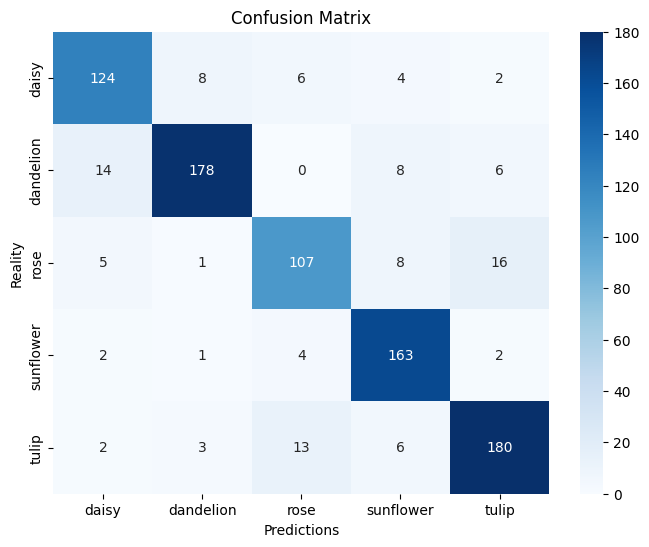

In [ ]:
FOLDER_TEST = "/content/drive/MyDrive/images"
MODEL_NAME = "/content/drive/MyDrive/mon_modele_fleurs.keras"
classes_name = ['daisy', 'dandelion', 'rose', 'sunflower', 'tulip']

#Drive saved model
model = tf.keras.models.load_model(MODEL_NAME)

fichiers = os.listdir(FOLDER_TEST)
images_found = 0

for nom_fichier in fichiers:
    if nom_fichier.lower().endswith(('.png', '.jpg', '.jpeg')):
        images_found += 1
        chemin_image = os.path.join(FOLDER_TEST, nom_fichier)

        #Load the image + resize them to 128,128
        image_raw = tf.keras.utils.load_img(chemin_image, target_size=(128, 128))
        image_tab = tf.keras.utils.img_to_array(image_raw)
        image_ready = np.expand_dims(image_tab, axis=0)

        predictions = modele.predict(image_ready, verbose=0)

        winning_index = np.argmax(predictions[0])
        score = 100 * np.max(predictions[0])
        name_found = classes_name[winning_index].upper()

        nom_affichage = nom_fichier[:18] + ".." if len(nom_fichier) > 20 else nom_fichier
        print(f"File : {nom_affichage:<20} | {name_found:<10} | Accuracy : {score:>6.2f} %")

        plt.figure(figsize=(3, 3))
        plt.imshow(image_raw)
        plt.title(f"{name_found} ({score:.1f}%)")
        plt.axis('off')
        plt.show()

if images_found == 0:
    print("Images not found")

def curves(hist):
    acc = hist.history['accuracy']
    val_acc = hist.history['val_accuracy']
    loss = hist.history['loss']
    val_loss = hist.history['val_loss']
    epochs_range = range(len(acc))

    plt.figure(figsize=(12, 4))
    plt.subplot(1, 2, 1)
    plt.plot(epochs_range, acc, label='Training')
    plt.plot(epochs_range, val_acc, label='Validation')
    plt.title('Accuracy')
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(epochs_range, loss, label='Training')
    plt.plot(epochs_range, val_loss, label='Validation')
    plt.title('Loss')
    plt.legend()
    plt.show()

curves(historique)
y_true = []
y_pred = []

for images, labels in dataset_validation:
    preds = modele.predict(images, verbose=0)
    y_true.extend(labels.numpy())
    y_pred.extend(np.argmax(preds, axis=1))

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', xticklabels=flowers_name, yticklabels=flowers_name, cmap='Blues')
plt.xlabel('Predictions')
plt.ylabel('Reality')
plt.title('Confusion Matrix')
plt.show()

modele.save('optimize_flower_model.keras')